
<h2 style="border:2px solid #AA5E7A;border-radius:100%; padding:20px; margin:0; color:#AA5E7A; text-align:center"> Exploratory Data Analysis</h2>


In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
from scipy import stats

In [2]:
df=pd.read_csv('../../data/processed/employee_clean.csv')

numcols=df.select_dtypes('number').columns
catcols=['Gender','EducationBackground','MaritalStatus','EmpDepartment','EmpJobRole','BusinessTravelFrequency','OverTime','Attrition']
df.shape

(1200, 28)

## Univariate analysis
### A1 Target: PerformanceRating
Most employees are rated 3. Because the classes are imbalanced, accuracy alone can mislead, so macro-F1 is used when comparing models.

                   count  percent
PerformanceRating                
2                    194     16.2
3                    874     72.8
4                    132     11.0


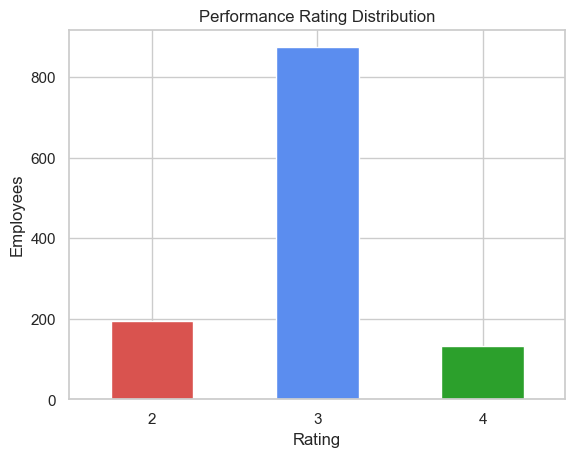

In [3]:
vc = df.PerformanceRating.value_counts().sort_index()

print(
    pd.DataFrame({
        'count': vc,
        'percent': (vc / len(df) * 100).round(1)
    })
)

ax = vc.plot(
    kind='bar',
    color=['#d9534f', '#5b8def', '#2ca02c'],
    rot=0
)

ax.set_title('Performance Rating Distribution')
ax.set_xlabel('Rating')
ax.set_ylabel('Employees')

plt.show()

### A2 Numeric columns

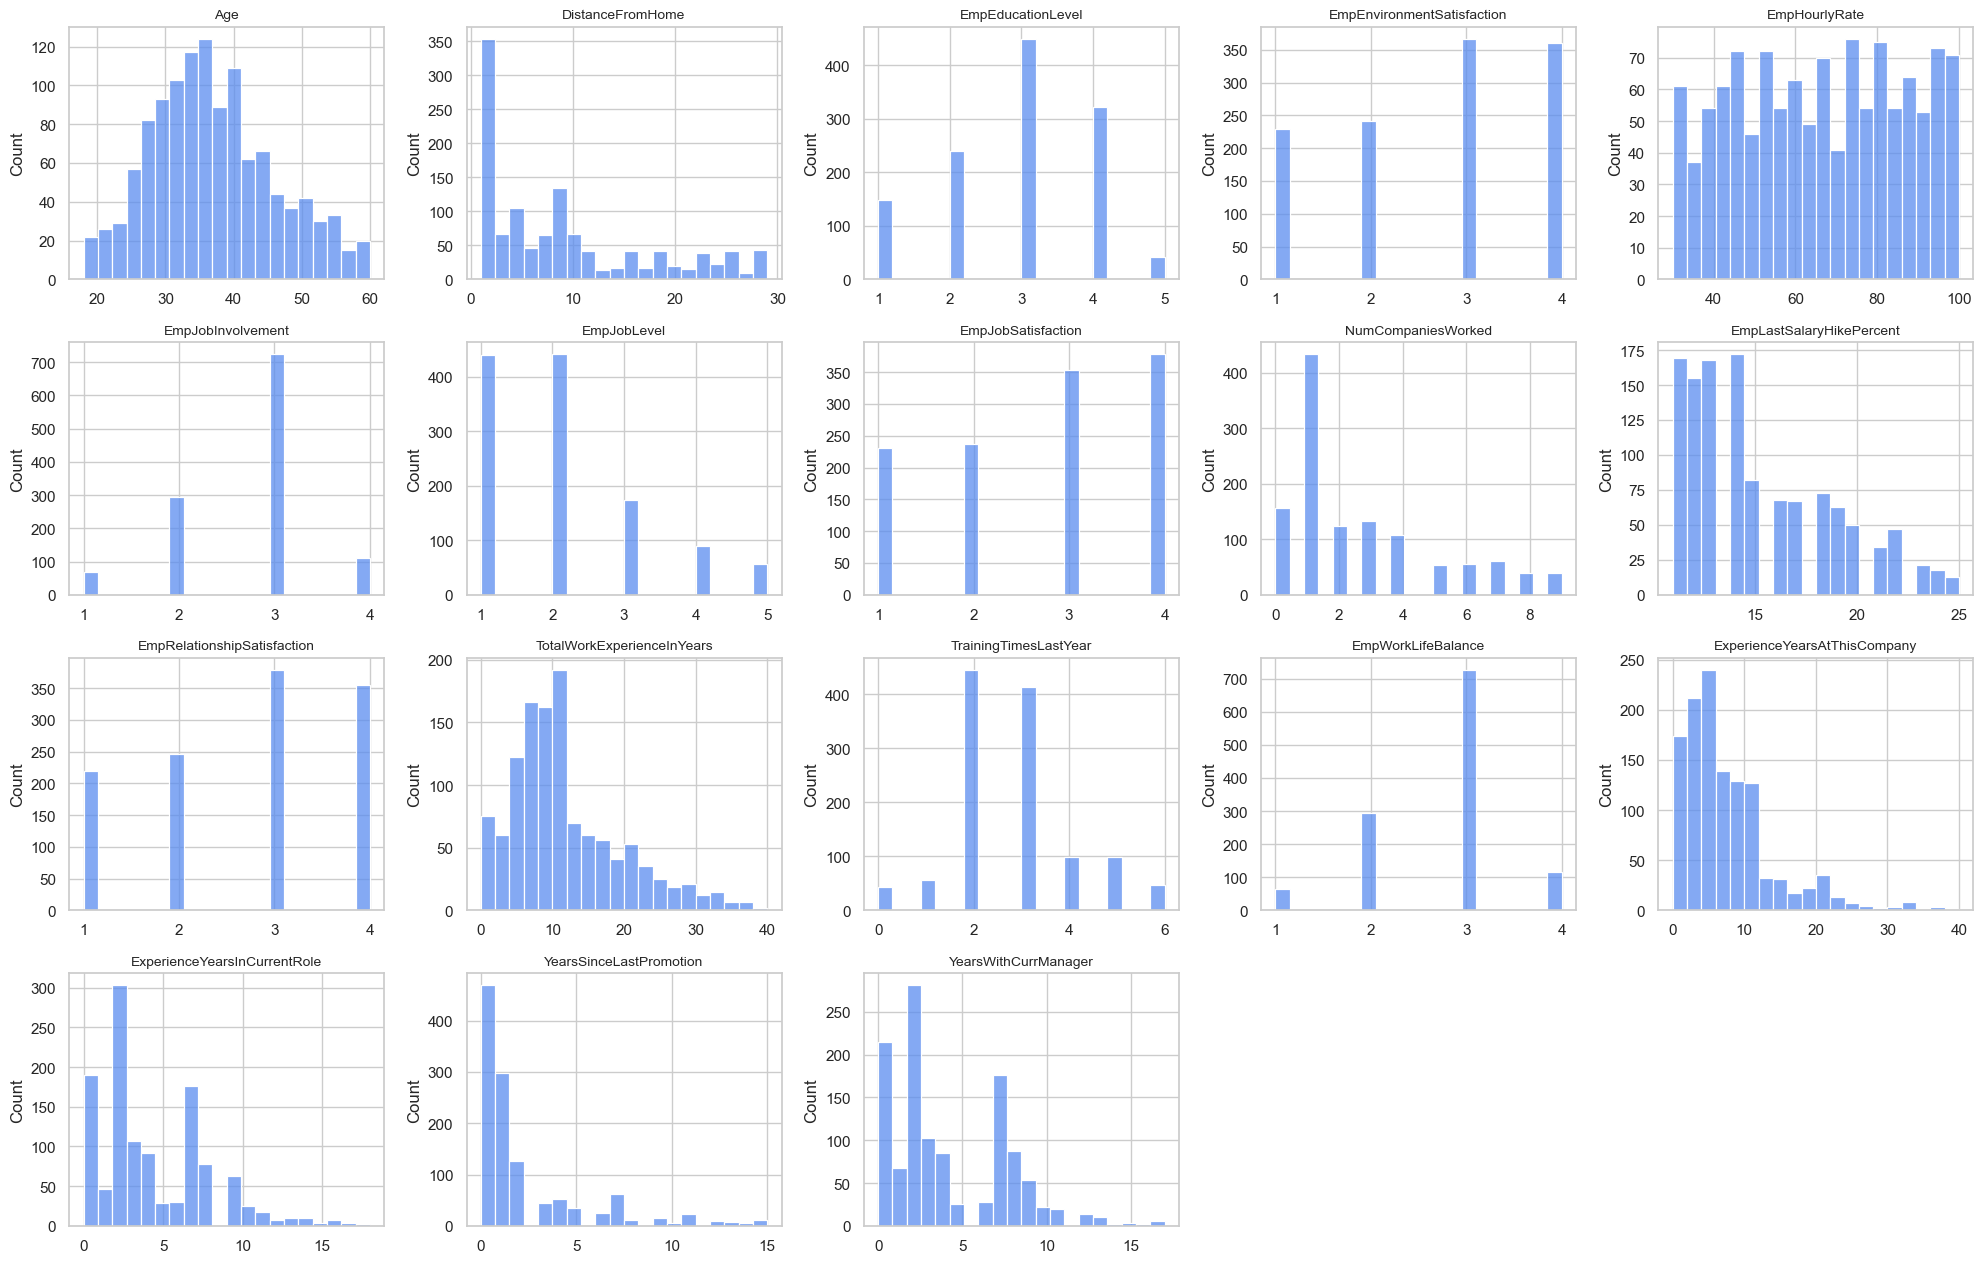

In [4]:
cols = list(numcols.drop('PerformanceRating'))

n = len(cols)
r = int(np.ceil(n / 5))

fig, axes = plt.subplots(r, 5, figsize=(20, 3.2 * r))

for a, c in zip(axes.ravel(), cols):
    sns.histplot(
        df[c],
        bins=20,
        ax=a,
        color='#5b8def'
    )
    a.set_title(c, fontsize=10)
    a.set_xlabel('')

for a in axes.ravel()[n:]:
    a.axis('off')

plt.tight_layout()

plt.show()

**Reading:** age, experience and tenure are right-skewed (many newer employees, few very long careers). The satisfaction and involvement scores are on small 1-4 scales. Salary hike % ranges from 11 to 25.

### A3 Categorical columns

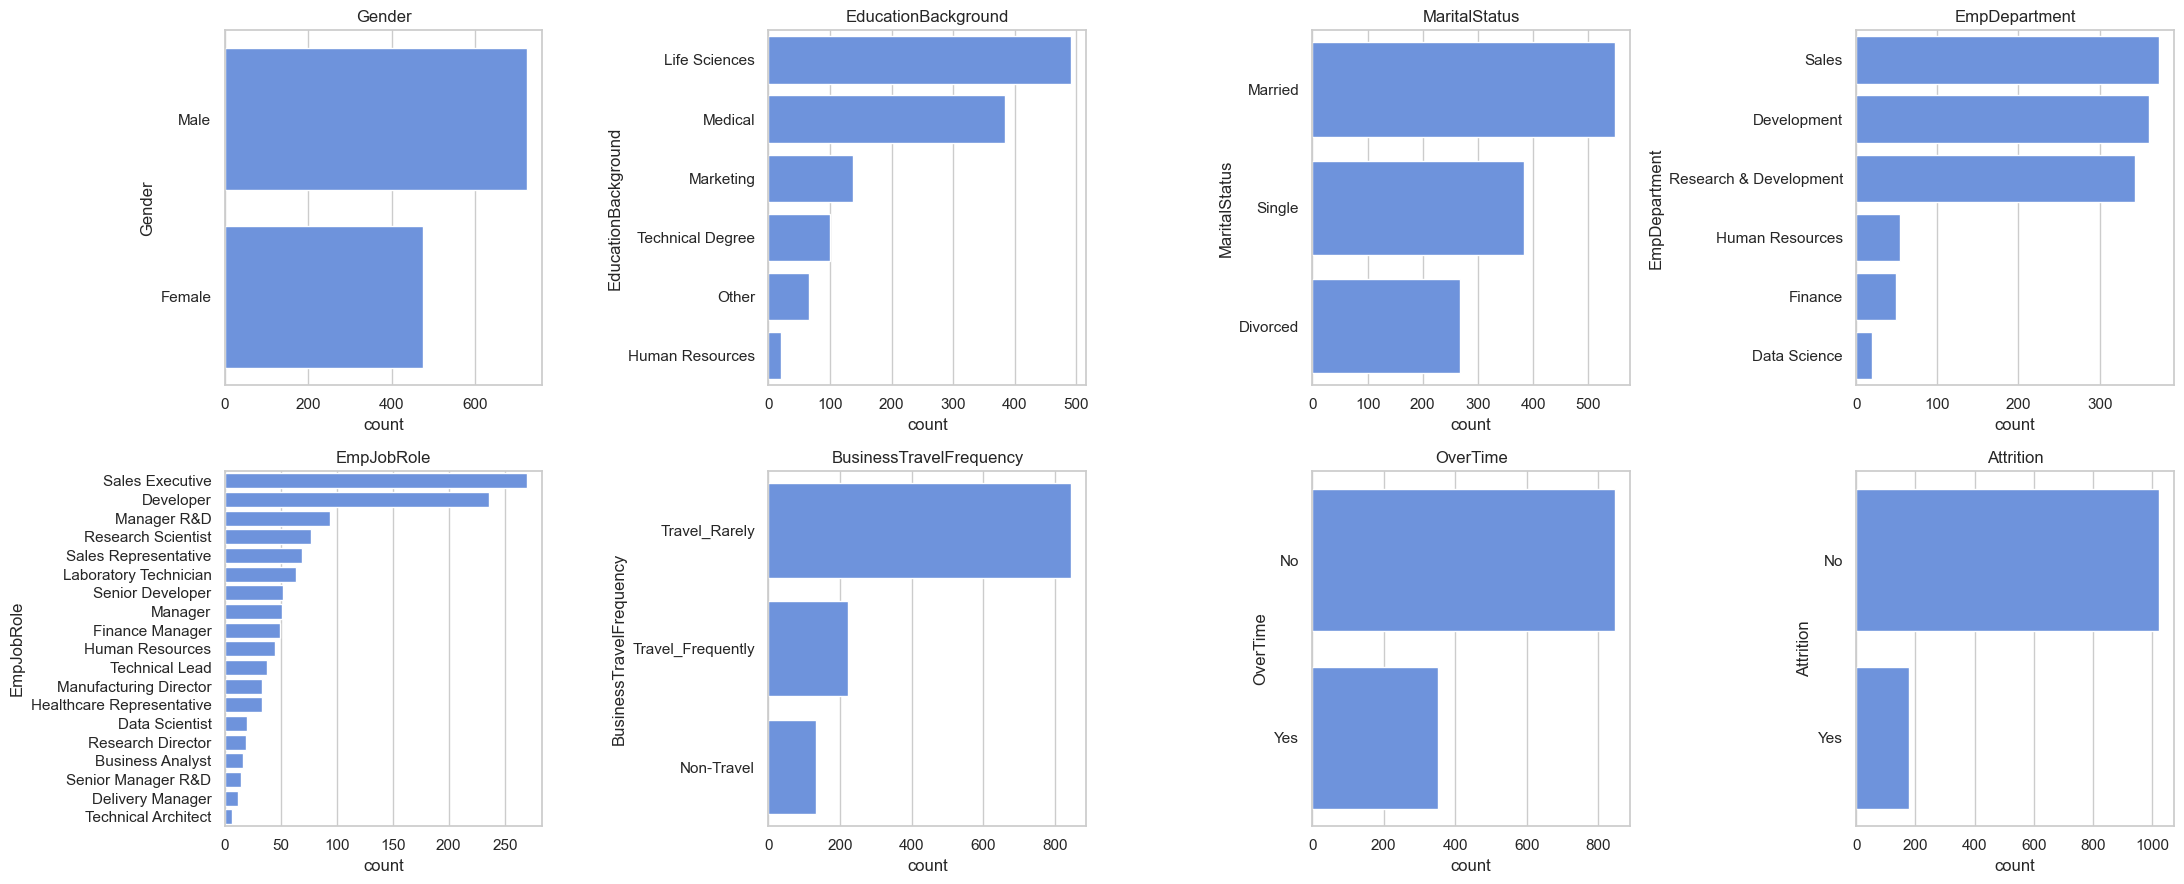

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9))

for a, c in zip(axes.ravel(), catcols):
    order = df[c].value_counts().index

    sns.countplot(
        data=df,
        y=c,
        order=order,
        ax=a,
        color='#5b8def'
    )

    a.set_title(c)

plt.tight_layout()
plt.show()

## Bivariate analysis
### B1 Insight 1 – Department-wise performance

In [6]:
dept=df.groupby('EmpDepartment').PerformanceRating.agg(mean='mean',employees='count').round(3)
share=pd.crosstab(df.EmpDepartment,df.PerformanceRating,normalize='index').mul(100).round(1)
share.columns=['Rating 2 %','Rating 3 %','Rating 4 %']
dept=dept.join(share).sort_values('mean',ascending=False)
dept.to_csv('../../reports/department_performance.csv')
dept

,mean,employees,Rating 2 %,Rating 3 %,Rating 4 %
EmpDepartment,,,,,
Development,3.086,361,3.6,84.2,12.2
Data Science,3.050,20,5.0,85.0,10.0
Human Resources,2.926,54,18.5,70.4,11.1
Research & Development,2.921,343,19.8,68.2,12.0
Sales,2.861,373,23.3,67.3,9.4
Finance,2.776,49,30.6,61.2,8.2


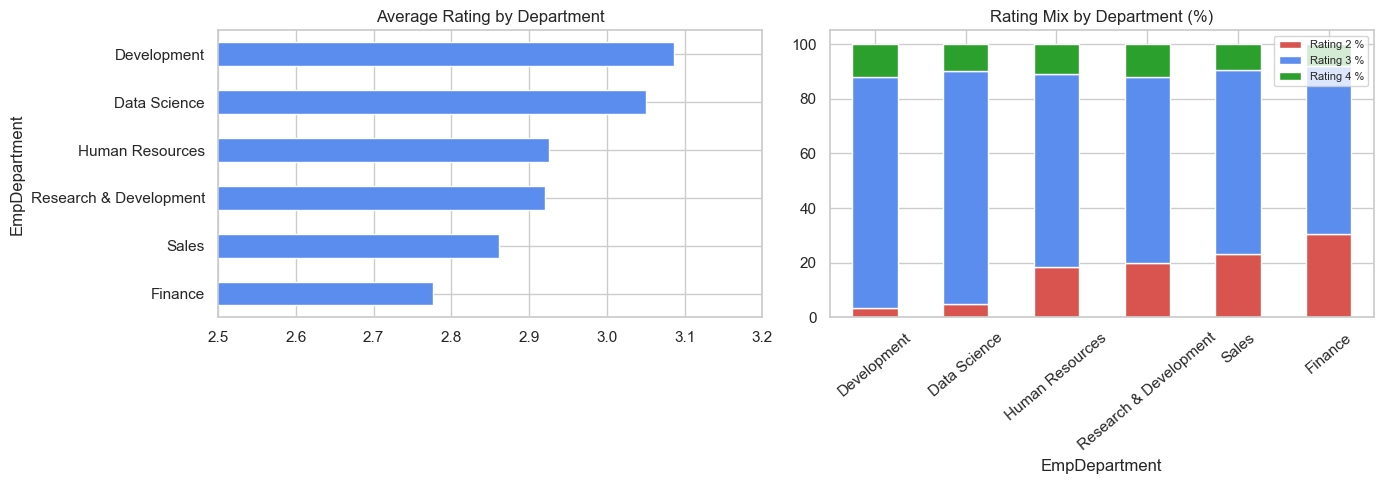

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

dept['mean'].sort_values().plot(
    kind='barh',
    ax=ax[0],
    color='#5b8def'
)

ax[0].set_title('Average Rating by Department')
ax[0].set_xlim(2.5, 3.2)


share.loc[dept.index].plot(
    kind='bar',
    stacked=True,
    ax=ax[1],
    color=['#d9534f', '#5b8def', '#2ca02c']
)

ax[1].set_title('Rating Mix by Department (%)')
ax[1].legend(loc='upper right', fontsize=8)
ax[1].tick_params(axis='x', rotation=40)

plt.tight_layout()
plt.show()

In [8]:
ct=pd.crosstab(df.EmpDepartment,df.PerformanceRating)
chi2,p,_,_=stats.chi2_contingency(ct)
print(f'Chi-square department vs rating: chi2={chi2:.1f}, p={p:.2e}')
print('Employees rated 2 by department:');
print(ct[2].sort_values(ascending=False))

Chi-square department vs rating: chi2=70.3, p=3.83e-11
Employees rated 2 by department:
EmpDepartment
Sales                     87
Research & Development    68
Finance                   15
Development               13
Human Resources           10
Data Science               1
Name: 2, dtype: int64


**Reading:** Development and Data Science perform best. Finance, Sales and R&D carry the largest share of low ratings. The differences between departments are statistically significant.

In [9]:
role=df.groupby(['EmpDepartment','EmpJobRole']).PerformanceRating.agg(mean='mean',n='count').round(2).sort_values('mean')
role['pct_rated_2']=(df[df.PerformanceRating==2].groupby(['EmpDepartment','EmpJobRole']).size()/role.n*100).fillna(0).round(1)
role.to_csv('../../reports/jobrole_performance.csv');
role

mean    n  pct_rated_2
EmpDepartment          EmpJobRole                                       
Finance                Finance Manager            2.78   49         30.6
Research & Development Senior Manager R&D         2.80   15         26.7
                       Healthcare Representative  2.85   33         24.2
                       Laboratory Technician      2.86   64         21.9
Sales                  Sales Executive            2.86  270         23.7
                       Sales Representative       2.87   69         17.4
                       Manager                    2.88   34         32.4
Research & Development Research Director          2.89   19         26.3
Human Resources        Human Resources            2.91   45         20.0
Research & Development Manager R&D                2.94   94         18.1
                       Research Scientist         2.96   77         22.1
                       Manufacturing Director     2.97   33          9.1
Development            Senior Developer           3.00   52         11.5
Human Resources        Manager                    3.00    9         11.1
Development            Delivery Manager           3.00   12          0.0
                       Technical Architect        3.00    7          0.0
Data Science           Data Scientist             3.05   20          5.0
Development            Technical Lead             3.08   38          2.6
                       Developer                  3.11  236          2.5
                       Business Analyst           3.19   16          0.0
Research & Development Manager                    3.25    8          0.0

### B2 Numeric features against performance (Spearman correlation)
Spearman is used because the rating and most scores are ordinal.

YearsSinceLastPromotion        -0.270
ExperienceYearsInCurrentRole   -0.166
YearsWithCurrManager           -0.135
ExperienceYearsAtThisCompany   -0.132
EmpJobLevel                    -0.081
TotalWorkExperienceInYears     -0.074
EmpHourlyRate                  -0.045
DistanceFromHome               -0.038
Age                            -0.035
EmpRelationshipSatisfaction    -0.022
EmpJobInvolvement              -0.011
TrainingTimesLastYear           0.001
EmpJobSatisfaction              0.005
EmpEducationLevel               0.015
NumCompaniesWorked              0.038
EmpWorkLifeBalance              0.114
EmpLastSalaryHikePercent        0.274
EmpEnvironmentSatisfaction      0.397
Name: PerformanceRating, dtype: float64


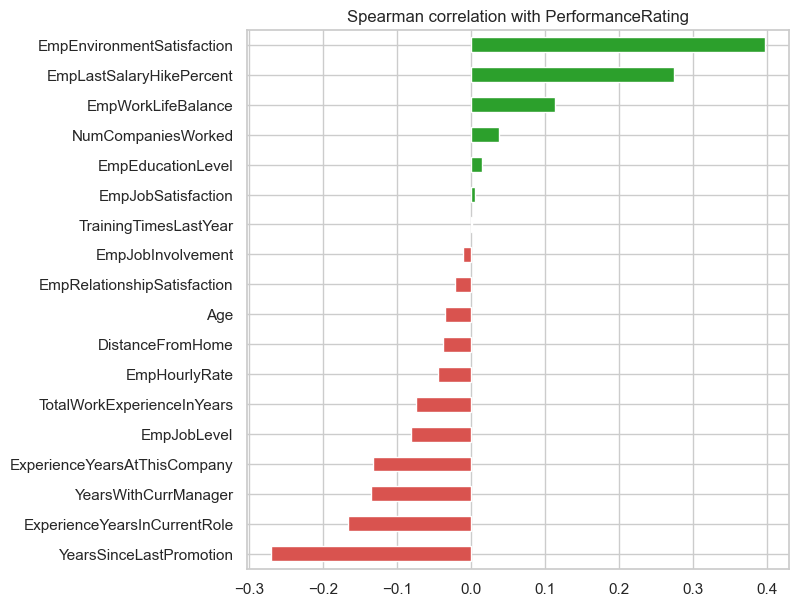

In [10]:
corr=df[numcols].corr(method='spearman')['PerformanceRating'].drop('PerformanceRating').sort_values()
print(corr.round(3))
plt.figure(figsize=(7,7));
corr.plot(kind='barh',color=np.where(corr>0,'#2ca02c','#d9534f')); 
plt.title('Spearman correlation with PerformanceRating')
plt.show()

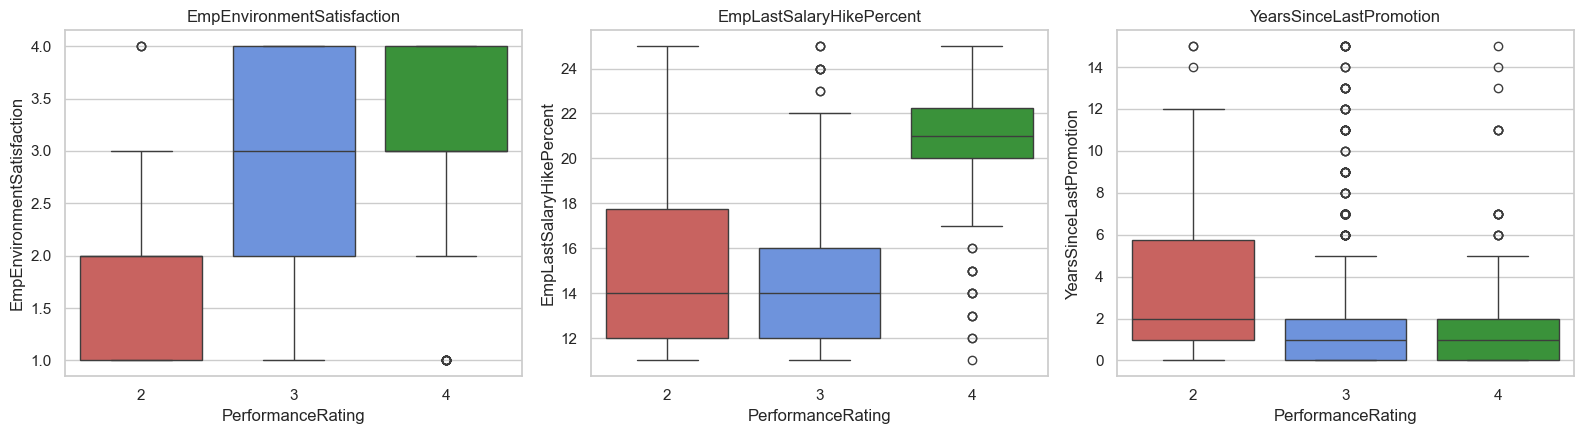

,EmpEnvironmentSatisfaction,EmpLastSalaryHikePercent,YearsSinceLastPromotion,EmpWorkLifeBalance
PerformanceRating,,,,
2,1.58,15.07,3.70,2.63
3,2.91,14.43,1.91,2.73
4,3.08,20.70,1.86,2.99


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

for a, col in zip(
    ax,
    [
        'EmpEnvironmentSatisfaction',
        'EmpLastSalaryHikePercent',
        'YearsSinceLastPromotion'
    ]
):
    sns.boxplot(
        data=df,
        x='PerformanceRating',
        y=col,
        ax=a,
        palette=['#d9534f', '#5b8def', '#2ca02c']
    )

    a.set_title(col)

plt.tight_layout()


plt.show()


df.groupby('PerformanceRating')[
    [
        'EmpEnvironmentSatisfaction',
        'EmpLastSalaryHikePercent',
        'YearsSinceLastPromotion',
        'EmpWorkLifeBalance'
    ]
].mean().round(2)

### B3 Employee satisfaction
Average rating and share rated 2 at each level of every satisfaction score.

In [12]:
sat=['EmpEnvironmentSatisfaction','EmpJobSatisfaction','EmpRelationshipSatisfaction','EmpWorkLifeBalance','EmpJobInvolvement']
rows=[]
for c in sat:
    g=df.groupby(c).PerformanceRating.agg(avg='mean',pct_rated_2=lambda s:(s==2).mean()*100,n='count').round(2); g.insert(0,'score',c); rows.append(g.reset_index(names='level'))
pd.concat(rows).set_index(['score','level'])

avg  pct_rated_2    n
score                       level                        
EmpEnvironmentSatisfaction  1      2.67        39.13  230
                            2      2.65        40.50  242
                            3      3.14         0.82  367
                            4      3.13         0.83  361
EmpJobSatisfaction          1      2.97        16.45  231
                            2      2.95        12.66  237
                            3      2.90        19.21  354
                            4      2.98        15.34  378
EmpRelationshipSatisfaction 1      2.95        17.35  219
                            2      2.96        15.38  247
                            3      2.97        14.51  379
                            4      2.92        17.75  355
EmpWorkLifeBalance          1      2.75        25.00   64
                            2      2.92        17.35  294
                            3      2.95        15.82  727
                            4      3.12        10.43  115
EmpJobInvolvement           1      2.96        18.57   70
                            2      2.96        15.65  294
                            3      2.94        16.30  724
                            4      2.95        15.18  112

**Reading:** environment satisfaction is by far the strongest satisfaction link. At levels 1-2 about 40% are rated 2; at levels 3-4 only about 1%. Job satisfaction, relationship satisfaction and involvement show almost no link with rating. Work-life balance has a small positive link.

### B4 Experience, pay and training

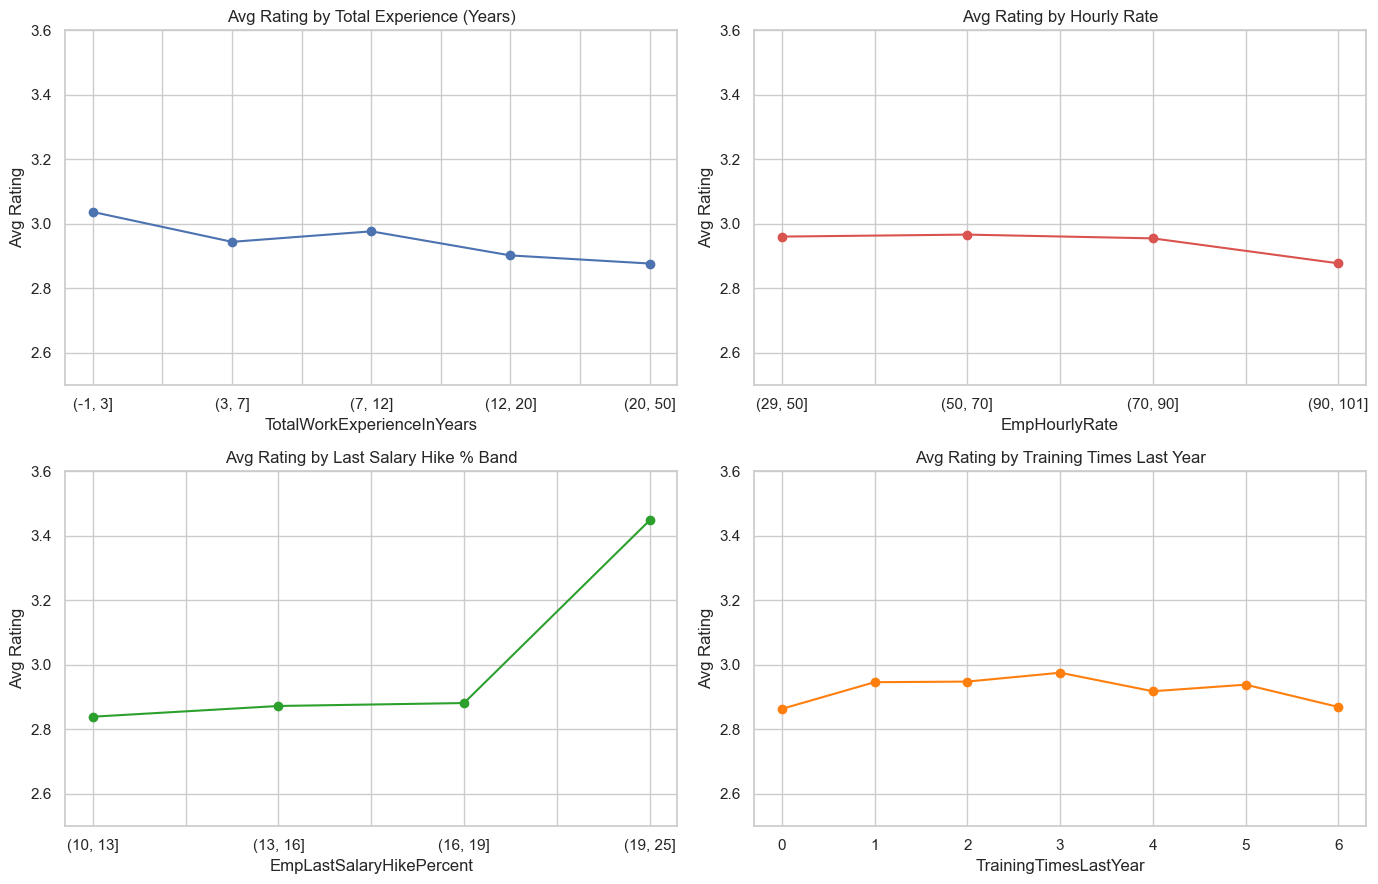

Rated 4 when last salary hike >=20%: 61%   below 20%: 2%
Spearman with rating: training times = 0.001, hourly rate = -0.045, total experience = -0.074


In [13]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

b = pd.cut(
    df.TotalWorkExperienceInYears,
    [-1, 3, 7, 12, 20, 50]
)

df.groupby(b, observed=True).PerformanceRating.mean().plot(
    marker='o',
    ax=ax[0, 0]
)

ax[0, 0].set_title('Avg Rating by Total Experience (Years)')


b = pd.cut(
    df.EmpHourlyRate,
    [29, 50, 70, 90, 101]
)

df.groupby(b, observed=True).PerformanceRating.mean().plot(
    marker='o',
    ax=ax[0, 1],
    color='#d9534f'
)

ax[0, 1].set_title('Avg Rating by Hourly Rate')


b = pd.cut(
    df.EmpLastSalaryHikePercent,
    [10, 13, 16, 19, 25]
)

df.groupby(b, observed=True).PerformanceRating.mean().plot(
    marker='o',
    ax=ax[1, 0],
    color='#2ca02c'
)

ax[1, 0].set_title('Avg Rating by Last Salary Hike % Band')


df.groupby('TrainingTimesLastYear').PerformanceRating.mean().plot(
    marker='o',
    ax=ax[1, 1],
    color='#ff7f0e'
)

ax[1, 1].set_title('Avg Rating by Training Times Last Year')


for a in ax.ravel():
    a.set_ylabel('Avg Rating')
    a.set_ylim(2.5, 3.6)

plt.tight_layout()


plt.show()


print(
    'Rated 4 when last salary hike >=20%%: %.0f%%   below 20%%: %.0f%%'
    % (
        (df[df.EmpLastSalaryHikePercent >= 20].PerformanceRating == 4).mean() * 100,
        (df[df.EmpLastSalaryHikePercent < 20].PerformanceRating == 4).mean() * 100
    )
)


print(
    'Spearman with rating: training times = %.3f, hourly rate = %.3f, total experience = %.3f'
    % tuple(
        df[c].corr(df.PerformanceRating, method='spearman')
        for c in [
            'TrainingTimesLastYear',
            'EmpHourlyRate',
            'TotalWorkExperienceInYears'
        ]
    )
)

**Reading:** experience and hourly rate show little or slightly negative links. The size of the **last salary hike** matters: employees with hikes of 20% or more are mostly rated 4. **The number of training sessions last year shows no link with rating.** Raises may follow good ratings, so this is an association and not proof of cause.

## B5 Categorical features against performance (chi-square test)

In [14]:

rows=[]
for c in catcols:
    chi2,p,_,_=stats.chi2_contingency(pd.crosstab(df[c],df.PerformanceRating)); 
    rows.append((c,round(chi2,1),p,'Significant' if p<0.05 else 'Not significant'))
pd.DataFrame(rows,columns=['Feature','Chi2','p-value','Result at 5%']).sort_values('p-value')

,Feature,Chi2,p-value,Result at 5%
3,EmpDepartment,70.3,3.832079e-11,Significant
4,EmpJobRole,97.7,1.311060e-07,Significant
6,OverTime,11.3,3.548518e-03,Significant
2,MaritalStatus,6.1,1.894104e-01,Not significant
7,Attrition,2.6,2.770535e-01,Not significant
5,BusinessTravelFrequency,4.4,3.549025e-01,Not significant
1,EducationBackground,10.2,4.216327e-01,Not significant
0,Gender,0.2,9.217557e-01,Not significant


Department and job role (which overlap) show the clearest link. OverTime also tests as significant but in a surprising direction: employees *without* overtime are rated 2 slightly more often (18% vs 11%). This is a weak pattern and not a cause. Gender, marital status, education background, travel frequency and attrition show no significant link.

## Part C – Multivariate analysis
### C1 Correlation heatmap and multicollinearity

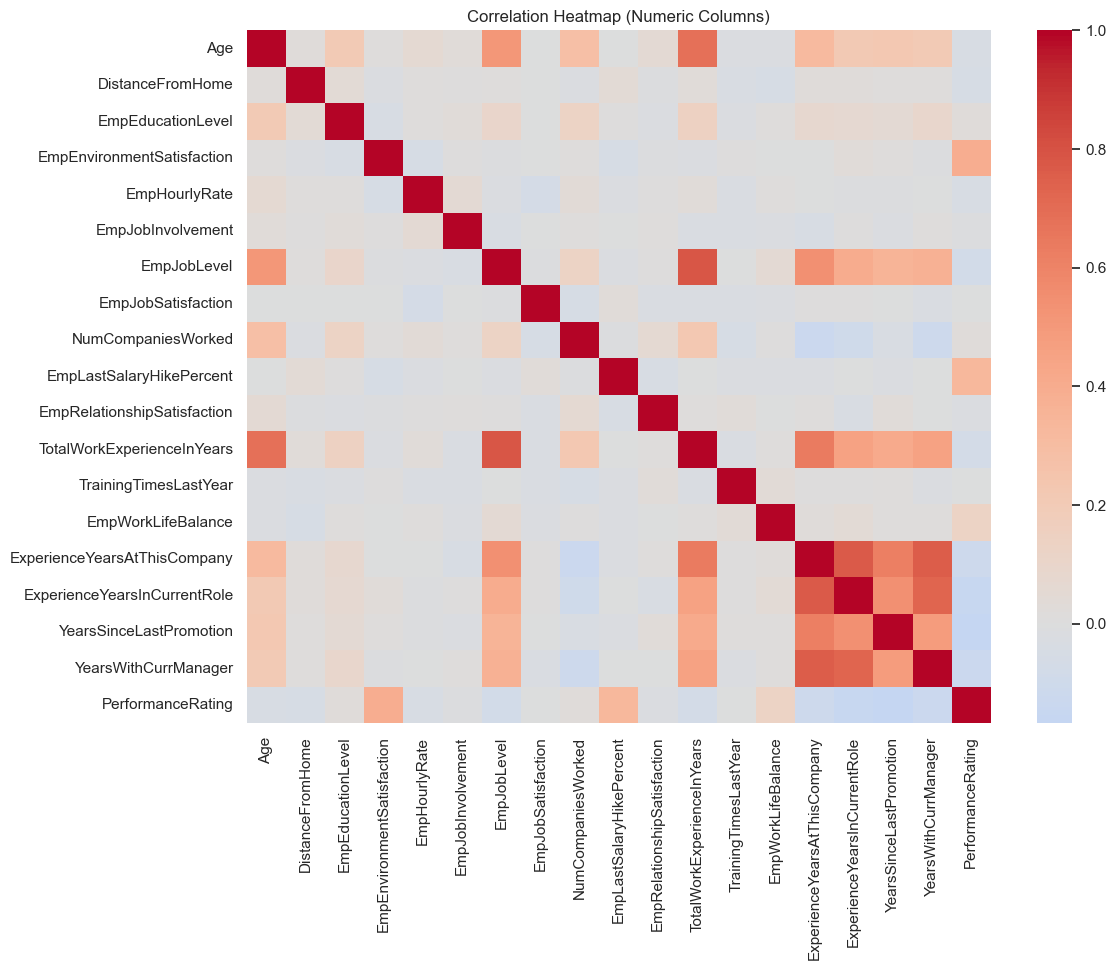

abs correlation
EmpJobLevel                  TotalWorkExperienceInYears           0.784229
ExperienceYearsAtThisCompany ExperienceYearsInCurrentRole         0.764102
                             YearsWithCurrManager                 0.759258
ExperienceYearsInCurrentRole YearsWithCurrManager                 0.728973
Age                          TotalWorkExperienceInYears           0.680886
TotalWorkExperienceInYears   ExperienceYearsAtThisCompany         0.633555
ExperienceYearsAtThisCompany YearsSinceLastPromotion              0.620230

In [15]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    df[numcols].corr(),
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap (Numeric Columns)')


plt.show()


c = df[numcols.drop('PerformanceRating')].corr().abs()

pairs = (
    c.where(np.triu(np.ones(c.shape), 1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)

pairs[pairs > 0.6].to_frame('abs correlation')

Age, total experience, tenure, role experience, years with manager and job level move together (as expected). The prediction models handle this: tree ensembles are not hurt by correlated inputs, and linear models use scaling and regularisation. Importance is later measured on whole original columns with permutation importance.

### C2 Combining two factors

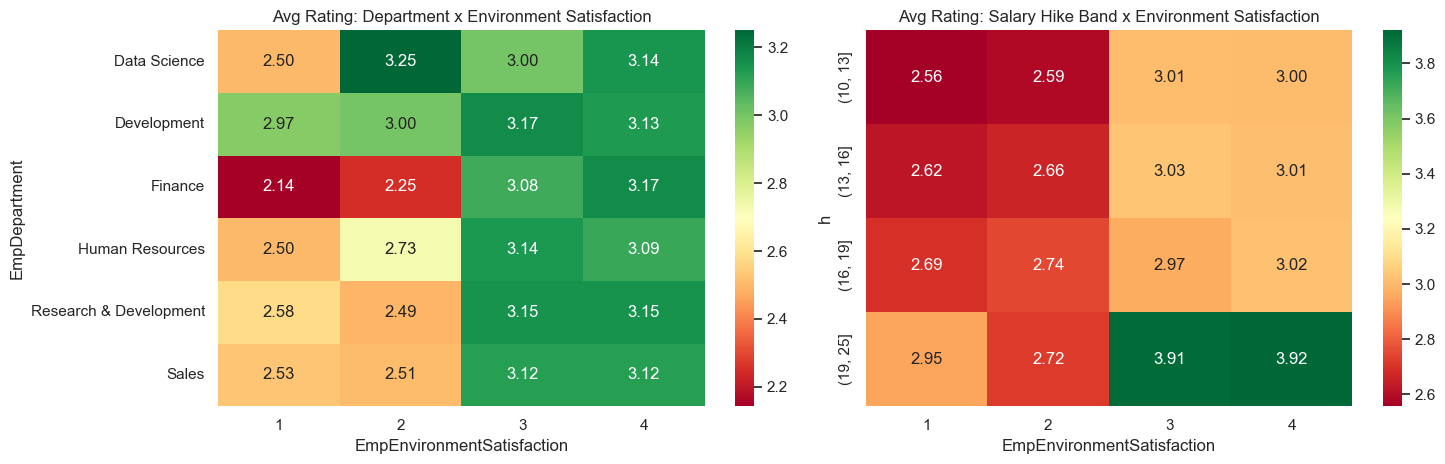

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))

sns.heatmap(
    df.pivot_table(
        index='EmpDepartment',
        columns='EmpEnvironmentSatisfaction',
        values='PerformanceRating',
        aggfunc='mean'
    ),
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    ax=ax[0]
)

ax[0].set_title('Avg Rating: Department x Environment Satisfaction')


b = pd.cut(
    df.EmpLastSalaryHikePercent,
    [10, 13, 16, 19, 25]
).astype(str)

sns.heatmap(
    df.assign(h=b).pivot_table(
        index='h',
        columns='EmpEnvironmentSatisfaction',
        values='PerformanceRating',
        aggfunc='mean'
    ),
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    ax=ax[1]
)

ax[1].set_title('Avg Rating: Salary Hike Band x Environment Satisfaction')

plt.tight_layout()


plt.show()

In all six departments, employees with environment satisfaction 1-2 average lower ratings than those at 3-4, so the satisfaction effect is not just a department effect (Data Science has only 6 such employees, so treat that department as indicative). The gap is widest in Finance (about 2.2 vs 3.1) and smallest in Development and Data Science.

### C3 Profile of low performers (rating 2)
The CEO wants clear indicators so that any action targets the right people.

In [17]:
low=df[df.PerformanceRating==2]; rest=df[df.PerformanceRating!=2]
cols=['EmpEnvironmentSatisfaction','EmpLastSalaryHikePercent','YearsSinceLastPromotion','EmpWorkLifeBalance','ExperienceYearsInCurrentRole','Age','EmpJobSatisfaction','TrainingTimesLastYear']
prof=pd.DataFrame({'Low (rating 2)':low[cols].mean(),'Others':rest[cols].mean()}).round(2); prof['Gap']=(prof.iloc[:,0]-prof.iloc[:,1]).round(2)
print(prof)
print('\nShare of rating-2 employees with environment satisfaction 1-2: %.0f%%  (others: %.0f%%)'%((low.EmpEnvironmentSatisfaction<=2).mean()*100,(rest.EmpEnvironmentSatisfaction<=2).mean()*100))
print('Rated 2 when environment satisfaction is 1-2: %.0f%%   when it is 3-4: %.0f%%'%((df[df.EmpEnvironmentSatisfaction<=2].PerformanceRating==2).mean()*100,(df[df.EmpEnvironmentSatisfaction>=3].PerformanceRating==2).mean()*100))
print('Attrition rate: rating 2 = %.1f%%, others = %.1f%%'%((low.Attrition=='Yes').mean()*100,(rest.Attrition=='Yes').mean()*100))

                              Low (rating 2)  Others   Gap
EmpEnvironmentSatisfaction              1.58    2.93 -1.35
EmpLastSalaryHikePercent               15.07   15.25 -0.18
YearsSinceLastPromotion                 3.70    1.90  1.80
EmpWorkLifeBalance                      2.63    2.77 -0.14
ExperienceYearsInCurrentRole            5.79    4.00  1.79
Age                                    37.80   36.75  1.05
EmpJobSatisfaction                      2.75    2.73  0.02
TrainingTimesLastYear                   2.76    2.79 -0.03

Share of rating-2 employees with environment satisfaction 1-2: 97%  (others: 28%)
Rated 2 when environment satisfaction is 1-2: 40%   when it is 3-4: 1%
Attrition rate: rating 2 = 18.6%, others = 14.1%


### C4 Summary of EDA findings
1. Ratings are skewed to 3 (about 73%); about 11% are 4 and 16% are 2.
2. Departments differ significantly: Development and Data Science do best; Finance, Sales and R&D carry most low ratings.
3. The strongest linked numeric features are environment satisfaction, last salary hike % and years since last promotion (negative).
4. A rating of 2 is concentrated among employees with environment satisfaction 1-2; a rating of 4 among those with hikes of 20% or more. These are associations, not proven causes.
5. Training frequency, job satisfaction, gender, marital status, education background and travel show no meaningful link with rating.
6. No missing values or duplicates were found.